# Bitwise AND and property usage flags

```gdscript
for p in script.get_script_property_list():
    if p.usage & PROPERTY_USAGE_EDITOR: properties.append(p)
```

Reads as: **keep only the `@export`ed variables, skip plain `var`s.**

- `get_script_property_list()` returns every variable the script declares, each as a dictionary with a `usage` integer.
- `usage` packs many on/off switches into one integer, one bit each.
- `&` keeps only the bits that are 1 in **both** numbers, so the result is non-zero only when that switch is on.

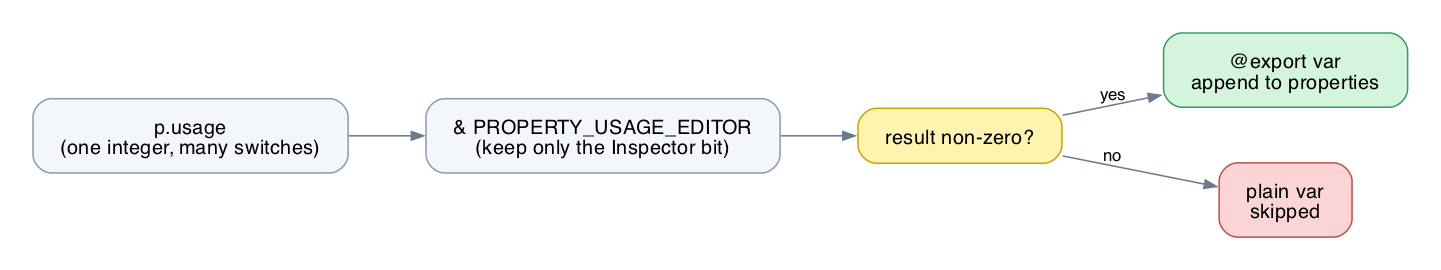

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  usage  [label="p.usage\n(one integer, many switches)"];
  mask   [label="& PROPERTY_USAGE_EDITOR\n(keep only the Inspector bit)"];
  check  [label="result non-zero?", fillcolor="#fff3b0", color="#c9a400"];
  keep   [label="@export var\nappend to properties", fillcolor="#d4f4dd", color="#3c9a5f"];
  skip   [label="plain var\nskipped", fillcolor="#fbd5d5", color="#c0504d"];
  usage -> mask -> check;
  check -> keep [label="yes"];
  check -> skip [label="no"];
}
```

</details>

## The same line, on two variables

| Declaration | `usage` | In binary | `usage & 4` | Kept? |
|---|---|---|---|---|
| `@export var messages` | 4102 | `1 0000 0000 0110` | `100` = 4 | yes |
| `var _timer` | 4096 | `1 0000 0000 0000` | `000` = 0 | no |
| `PROPERTY_USAGE_EDITOR` (the mask) | 4 | `0 0000 0000 0100` | | |

**`&` versus `and`:** `and` only asks "are both values non-zero?" and answers true/false. Both rows above would be true, so `and` would keep the plain `var` too. `&` compares bit by bit and answers with an integer.

Where it was used: `exported_properties()` in the RPGM plugin's lambda helper, feeding the hand-built value editors. The popup now holds a real `EditorInspector`, which does this filtering itself, so the function was removed.

In [ ]:
# Python uses the same operators as GDScript here, so this runs as is.
PROPERTY_USAGE_STORAGE         = 2      # save to file
PROPERTY_USAGE_EDITOR          = 4      # show in Inspector
PROPERTY_USAGE_SCRIPT_VARIABLE = 4096   # declared in a script

properties = [
    {"name": "messages (@export var)", "usage": 4096 | 4 | 2},
    {"name": "_timer   (plain var)",   "usage": 4096},
]

for p in properties:
    bitwise = p["usage"] & PROPERTY_USAGE_EDITOR
    logical = bool(p["usage"] and PROPERTY_USAGE_EDITOR)
    print(f'{p["name"]:24} usage={p["usage"]:<5} {p["usage"]:013b}   & -> {bitwise}   and -> {logical}')

messages (@export var)   usage=4102  1000000000110   & -> 4   and -> True
_timer   (plain var)     usage=4096  1000000000000   & -> 0   and -> True


In [ ]:
# ----- student scratchpad -----